# 04 - Dark matter: profiles, J-factors, spectra and the annihilation model

The DM annihilation prior is a `TwoCompFluxPrior` with

$$\frac{d\phi}{dE\,d\Omega} = \frac{\langle\sigma v\rangle}{8\pi\, S_\chi\, m_\chi^2}\,
   \sum_c B_c\,\frac{dN_c}{dE}(E; m_\chi)\;\times\;\frac{dJ}{d\Omega}(l, b),
\qquad \frac{dJ}{d\Omega} = \int_\mathrm{los} \rho^2(r)\, ds .$$

* `Einasto_Profile`, `GNFW_Profile` (`DM_Profile` subclasses) are **spatial components** that
  return $\log dJ/d\Omega$ in TeV² cm⁻⁵ deg⁻², batched over their shape parameters;
* `SingleDMSpectralComp` is a **spectral component** interpolating the CosmiXs (default) or
  PPPC4DMID tables, with two systematic parameters: `kappa` (0 = CosmiXs, 1 = PPPC, continuous
  geometric blend) and `delta` (QCD-uncertainty band in units of its +1σ edge); 
  (reminder again to reference and double check that tables are up-to-date, notes on installation page)
* `CustomDMRatiosModel` combines any set of channels with branching ratios into one prior;
  `SingleChannelDMPrior` is the one-channel shortcut.

In [1]:
import os, math, time
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")   # Apple MPS: run the few unsupported ops on the CPU
import numpy as np
import torch
import matplotlib.pyplot as plt
from astropy import units as u

FAST = os.environ.get("GAMMABAYES_DOCS_FAST", "0") == "1"
# device: GAMMABAYES_DOCS_DEVICE=cpu|cuda|mps, else CUDA > Apple MPS > CPU.  MPS has no float64, so it runs in float32.
device = os.environ.get("GAMMABAYES_DOCS_DEVICE") or ("cuda" if torch.cuda.is_available()
                                                      else "mps" if torch.backends.mps.is_available() else "cpu")
torch.set_default_dtype(torch.float32 if device == "mps" else torch.float64)   # float64 where available: exactness over speed
torch.set_default_device(device)                # GammaBayes objects are created on the default device
print(f"torch {torch.__version__} on {device} ({torch.get_default_dtype()}), FAST={FAST}")

from gammabayes import GammaBinning, GammaLogExposure
from gammabayes.response_functions import IRFExtractor
from gammabayes.dark_matter import Einasto_Profile, GNFW_Profile, SingleDMSpectralComp, CustomDMRatiosModel, SingleChannelDMPrior
npy = lambda t: t.detach().cpu().numpy()

geom = GammaBinning(energy_res=10, energy_min=0.1, energy_max=100., lon_res=10, lon_min=-3., lon_max=3., lat_res=10, lat_min=-3., lat_max=3.)
pointing = torch.tensor([0., 0.])
irfs = IRFExtractor(zenith_angle=20, hemisphere="South", prod_vers=5, pointing_dir=pointing, irf_time_seconds=180000)
logexp = GammaLogExposure(binning_geometry=geom, irfs=irfs, pointing_dirs=[pointing], live_times=500 * u.hr)
E = geom.energy_axis
ll = geom.shaped_grid[0, ..., 1:]
dlon = float(geom.lon_edges[1] - geom.lon_edges[0])
dlat = float(geom.lat_edges[1] - geom.lat_edges[0])

torch 2.15.0 on mps (torch.float32), FAST=False


/Volumes/Extreme SSD/GammaBayes/.gb_venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[wall time: 3.3 s]


## Density profiles

Profiles are normalised to the local density $\rho(r_\odot) = 3.9\times10^{-4}$ TeV cm⁻³
(0.39 GeV cm⁻³) at $r_\odot = 8.3$ kpc.  `log_profile_func(r, **shape)` is the raw profile with
the scale density fixed for the *default* shape parameters; the J-factor evaluation re-derives
the scale density for the shape parameters passed at call time, so changing `alpha` or `gamma` changes
the cusp, not the solar-neighbourhood density.

rho(r_sun) Einasto / NFW: 0.00039000000106170774 0.000389999826438725


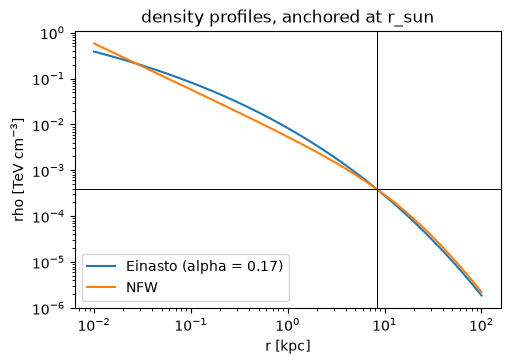

[wall time: 311 ms]


In [2]:
ein = Einasto_Profile()                       # alpha = 0.17, r_s = 20 kpc
nfw = GNFW_Profile()                          # alpha = 1, beta = 3, gamma = 1, r_s = 24.42 kpc  (= NFW)
r = torch.logspace(-2, 2, 200)                # kpc
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.loglog(npy(r), np.exp(npy(ein.log_profile_func(r))), label="Einasto (alpha = 0.17)")
ax.loglog(npy(r), np.exp(npy(nfw.log_profile_func(r))), label="NFW")
ax.axvline(8.3, color="k", lw=0.7)
ax.axhline(3.9e-4, color="k", lw=0.7)
ax.set(xlabel="r [kpc]", ylabel="rho [TeV cm$^{-3}$]", title="density profiles, anchored at r_sun")
ax.legend()
print("rho(r_sun) Einasto / NFW:", float(ein.log_profile_func(torch.tensor(8.3)).exp()), float(nfw.log_profile_func(torch.tensor(8.3)).exp()))

## J-factors

Calling a profile on a sky grid returns $\log dJ/d\Omega$ per deg².  The line of sight is
parametrised by the angle from the point of closest approach ($s = s_0 + b\tan u$), which makes
`int_resolution = 101` midpoints accurate to < 0.5 % for all offsets; the integral runs to
$4\,d_\odot$ and the impact parameter is floored at $10^{-3}$ deg for the pixel that contains the
GC exactly.  Shape parameters are batched like any other component parameter.

J(6x6 deg) Einasto = 3.03e+22 GeV^2 cm^-5,  NFW = 1.29e+22 GeV^2 cm^-5,  ratio = 2.34


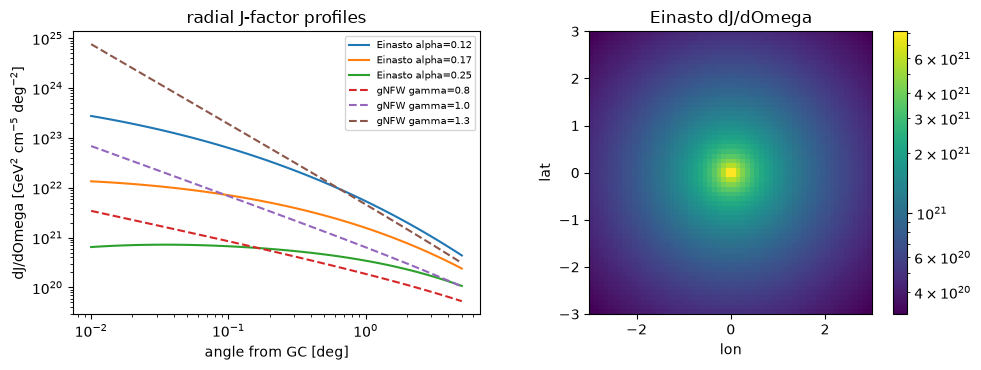

[wall time: 487 ms]


In [3]:
logJ_ein = ein(ll)                                        # (1, lon, lat)
logJ_nfw = nfw(ll)
J_win = lambda logJ: float(torch.exp(logJ[0]).sum() * dlon * dlat)          # TeV^2 cm^-5 over the window
print("J(6x6 deg) Einasto = %.3g GeV^2 cm^-5,  NFW = %.3g GeV^2 cm^-5,  ratio = %.2f" % (1e6 * J_win(logJ_ein), 1e6 * J_win(logJ_nfw), J_win(logJ_ein) / J_win(logJ_nfw)))

theta = torch.logspace(-2, 0.7, 60)                      # deg
ring = torch.stack([theta, torch.zeros_like(theta)], -1)[None]        # a (1, S, 2) "grid" along l at b = 0
alphas = torch.tensor([0.12, 0.17, 0.25])
prof_ein = ein(ring, alpha=alphas)[:, 0, :]                            # (3, S)
prof_nfw = nfw(ring, gamma=torch.tensor([0.8, 1.0, 1.3]))[:, 0, :]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for i, a in enumerate(alphas):
    ax[0].loglog(npy(theta), 1e6 * np.exp(npy(prof_ein[i])), label=f"Einasto alpha={float(a):.2f}")
for i, g in enumerate((0.8, 1.0, 1.3)):
    ax[0].loglog(npy(theta), 1e6 * np.exp(npy(prof_nfw[i])), "--", label=f"gNFW gamma={g}")
ax[0].set(xlabel="angle from GC [deg]", ylabel="dJ/dOmega [GeV$^2$ cm$^{-5}$ deg$^{-2}$]", title="radial J-factor profiles")
ax[0].legend(fontsize=7)
pcm = ax[1].pcolormesh(npy(geom.lon_axis), npy(geom.lat_axis), 1e6 * np.exp(npy(logJ_ein[0])).T, shading="auto", norm="log")
ax[1].set(xlabel="lon", ylabel="lat", aspect="equal", title="Einasto dJ/dOmega")
plt.colorbar(pcm, ax=ax[1])
plt.tight_layout()

The J-factor integral is differentiable with respect to the shape parameters.  Chunks of the
`(B, S, N_los)` integrand are gradient-checkpointed, so memory should stay bounded by `max_elems`,
especially under autograd (the forward pass is recomputed during the backward pass; without checkpointing the full integrand would not fit in memory).

In [4]:
alpha = torch.tensor(0.17, requires_grad=True)
J = torch.exp(ein(ll, alpha=alpha)[0]).sum() * dlon * dlat
dJ_dalpha, = torch.autograd.grad(J, alpha)
print("J = %.3e,  dJ/dalpha = %.3e  ->  dlnJ/dalpha = %.2f per unit alpha" % (J, dJ_dalpha, dJ_dalpha / J))

J = 3.034e+16,  dJ/dalpha = -6.012e+17  ->  dlnJ/dalpha = -19.82 per unit alpha


/Volumes/Extreme SSD/GammaBayes/.gb_venv/lib/python3.13/site-packages/torch/utils/_device.py:122: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:821.)
  return func(*args, **kwargs)


[wall time: 1.1 s]


## Annihilation spectra per channel

`SingleDMSpectralComp(channel, reader='cosmixs'|'pppc')` interpolates $\sqrt{dN/d\log_{10}x}$
on $(\log_{10} m_\chi, \log_{10} x)$, $x = E/m_\chi$, and returns $\log dN/dE$ in TeV⁻¹.  The
mass **must** be passed at call time.  Channel names follow the darkSUSY convention
(`'W+W-'`, `'ZZ'`, `'HH'`, `'tt'`, `'bb'`, `'cc'`, `'tau+tau-'`, `'mu+mu-'`, `'e+e-'`, `'gg'`,
`'gammagamma'`, ...).  Above $E = m_\chi$ the spectrum is floored at $e^{-50}E^{-3}$.

photons per W+W- annihilation above 0.1 TeV, m = 1 TeV: 0.6759025454521179


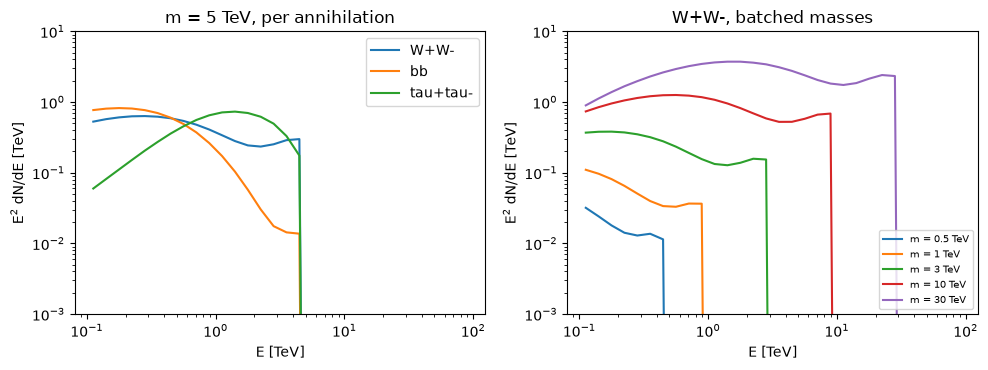

[wall time: 1.4 s]


In [5]:
ww, bb, tau = (SingleDMSpectralComp(channel=c) for c in ("W+W-", "bb", "tau+tau-"))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for comp, name in ((ww, "W+W-"), (bb, "bb"), (tau, "tau+tau-")):
    ax[0].loglog(npy(E), npy(E) ** 2 * np.exp(npy(comp(E, mass=5.0)[0])), label=name)
ax[0].set(xlabel="E [TeV]", ylabel="E$^2$ dN/dE [TeV]", title="m = 5 TeV, per annihilation", ylim=(1e-3, 10))
ax[0].legend()
masses = torch.tensor([0.5, 1., 3., 10., 30.])
spec = ww(E, mass=masses)                                              # (5, E) in one call
for i, m in enumerate(masses):
    ax[1].loglog(npy(E), npy(E) ** 2 * np.exp(npy(spec[i])), label=f"m = {float(m):g} TeV")
ax[1].set(xlabel="E [TeV]", ylabel="E$^2$ dN/dE [TeV]", title="W+W-, batched masses", ylim=(1e-3, 10))
ax[1].legend(fontsize=7)
plt.tight_layout()
# photons per annihilation above 0.1 TeV (integral of dN/dE over the energy grid)
dE = geom.energy_bin_widths
print("photons per W+W- annihilation above 0.1 TeV, m = 1 TeV:", float((torch.exp(ww(E, mass=1.0)[0]) * dE).sum()))

### Spectral systematics: `kappa` and `delta`

* `kappa` blends the central table with the other one in log space:
  $\log dN = (1-\kappa)\log dN_\mathrm{CosmiXs} + \kappa \log dN_\mathrm{PPPC}$.
* `delta` moves along the QCD-uncertainty band (hadronisation, shower scale and non-singular
  terms added in quadrature; Amoroso et al. 2019): `delta = 1` is the +1σ edge, `-1` the
  equivalent lower edge.

If a table is missing on your installation the corresponding parameter has **no effect** and a
one-time warning is printed when the component is created.

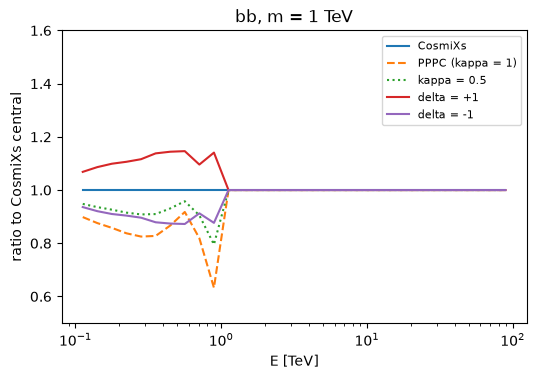

[wall time: 136 ms]


In [6]:
fig, ax = plt.subplots(figsize=(6, 3.8))
base = np.exp(npy(bb(E, mass=1.0)[0]))
for kappa, delta, ls, lab in ((0., None, "-", "CosmiXs"), (1., None, "--", "PPPC (kappa = 1)"), (0.5, None, ":", "kappa = 0.5"),
                              (0., 1., "-", "delta = +1"), (0., -1., "-", "delta = -1")):
    y = np.exp(npy(bb(E, mass=1.0, kappa=kappa, delta=delta)[0]))
    ax.semilogx(npy(E), y / base, ls, label=lab)
ax.set(xlabel="E [TeV]", ylabel="ratio to CosmiXs central", title="bb, m = 1 TeV", ylim=(0.5, 1.6))
ax.legend(fontsize=8)

## The annihilation model

`CustomDMRatiosModel` takes the channel list, a profile **class** (instantiated with
`spatial_profile_kwargs`) or instance, and the usual prior arguments.  Everything is passed
at evaluation time:

```python
model.eval_log_on_geom(spectral_params={"mass": m, "sigmav": sv, "ratios": r, "kappa": k, "delta": d},
                       spatial_params={"alpha": a})        # or {"gamma": g, "r_s": rs} for gNFW
```

`ratios` is a dict `{channel: value}` (missing channels are not allowed) or a `(B, n_ch)` tensor
in `model.channels` order; it is not normalised internally, so pass branching ratios that sum to one.
`sigmav` is in cm³ s⁻¹, `mass` in TeV; `symmetry_factor = 1` is the Majorana convention.

DM counts in 500 h, m = 1 TeV, <sigma v> = 1e-25: 303940.0


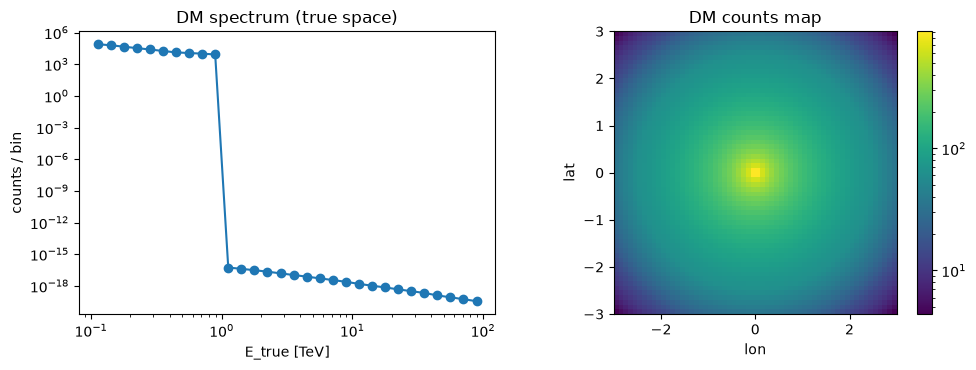

[wall time: 244 ms]


In [7]:
dm = CustomDMRatiosModel(binning_geometry=geom, channels=["W+W-", "bb", "tau+tau-"], spatial_profile=Einasto_Profile,
                         irf_loglike=irfs, log_exposure_map=logexp, name="DM")
spec = {"mass": 1.0, "sigmav": 1e-25, "ratios": {"W+W-": 0.6, "bb": 0.3, "tau+tau-": 0.1}}
spat = {"alpha": 0.17}
cube = dm.eval_log_on_geom(spectral_params=spec, spatial_params=spat)          # (E, lon, lat) log expected counts (true space)
counts = torch.exp(cube)
print("DM counts in 500 h, m = 1 TeV, <sigma v> = 1e-25:", float(counts.sum()))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].loglog(npy(E), npy(counts.sum((1, 2))), "o-")
ax[0].set(xlabel="E_true [TeV]", ylabel="counts / bin", title="DM spectrum (true space)")
pcm = ax[1].pcolormesh(npy(geom.lon_axis), npy(geom.lat_axis), npy(counts.sum(0)).T, shading="auto", norm="log")
ax[1].set(xlabel="lon", ylabel="lat", aspect="equal", title="DM counts map")
plt.colorbar(pcm, ax=ax[1])
plt.tight_layout()

### Separability and caching

The model exposes the two factors separately -- `log_spectrum` (`(B, E)`, prefactor
included) and `log_J` (`(B, lon, lat)`) -- and caches each one for small batches, so a
sampler that moves only the spectral parameters does not re-integrate the J-factor.  The cache
is bypassed whenever an input carries autograd state.

In [8]:
lS = dm.log_spectrum(**spec)                 # (1, E)
lJ = dm.log_J(**spat)                        # (1, lon, lat)
lX = logexp(geom.shaped_grid[..., 0].flatten(), geom.shaped_grid[..., 1].flatten(), geom.shaped_grid[..., 2].flatten()).reshape(geom.shape)
recon = lS[0, :, None, None] + lJ[0, None] + lX
fin = torch.isfinite(cube)
print("cube == spectrum + J + exposure:", torch.allclose(cube[fin], recon[fin]))
t0 = time.time()
dm.eval_log_on_geom(spectral_params=spec, spatial_params={"alpha": 0.20})
t1 = time.time()
dm.eval_log_on_geom(spectral_params=spec, spatial_params={"alpha": 0.20})
t2 = time.time()
print("new alpha: %.3f s   repeated call (both factors cached): %.3f s" % (t1 - t0, t2 - t1))

cube == spectrum + J + exposure: True
new alpha: 0.008 s   repeated call (both factors cached): 0.003 s


[wall time: 22 ms]


### Batched masses

A `(B,)` mass with scalar everything else gives `(B, E, lon, lat)`: a whole mass scan in one
call.  Memory is `B x E x lon x lat` doubles, so chunk large scans with
`gammabayes.core.batching.iter_batch_chunks`.

batched: (25, 30, 60, 60) in 0.01 s


[Text(0.5, 0, 'm_chi [TeV]'),
 Text(0, 0.5, 'DM counts above 0.1 TeV'),
 Text(0.5, 1.0, '<sigma v> = 1e-25 cm$^3$ s$^{-1}$, 500 h')]

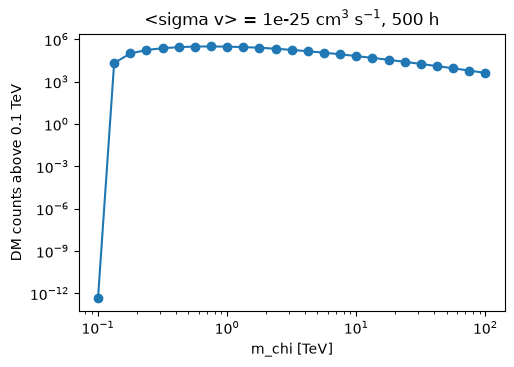

[wall time: 362 ms]


In [9]:
mass_grid = torch.logspace(-1, 2, 8 if FAST else 25)
t0 = time.time()
cubes = dm.eval_log_on_geom(spectral_params={**spec, "mass": mass_grid}, spatial_params=spat)
print("batched:", tuple(cubes.shape), "in %.2f s" % (time.time() - t0))
tot = torch.exp(cubes).sum((1, 2, 3))
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.loglog(npy(mass_grid), npy(tot), "o-")
ax.set(xlabel="m_chi [TeV]", ylabel="DM counts above 0.1 TeV", title="<sigma v> = 1e-25 cm$^3$ s$^{-1}$, 500 h")

### Gradients

Because the whole chain is torch, `d(counts)/d(parameter)` is one `autograd.grad` away --
including the J-factor shape parameters.

In [10]:
m = torch.tensor(1.0, requires_grad=True)
a = torch.tensor(0.17, requires_grad=True)
N = torch.exp(dm.eval_log_on_geom(spectral_params={**spec, "mass": m}, spatial_params={"alpha": a})).sum()
gm, ga = torch.autograd.grad(N, (m, a))
print("N = %.4g   dlnN/dln m = %.3f   dlnN/dalpha = %.3f" % (N, gm * m / N, ga / N))

N = 3.039e+05   dlnN/dln m = -0.285   dlnN/dalpha = -20.405


[wall time: 31 ms]


## Single-channel shortcut

`SingleChannelDMPrior` is the same object for one channel with no `ratios` parameter.

In [11]:
single = SingleChannelDMPrior(channel="W+W-", binning_geometry=geom, spatial_profile=Einasto_Profile, irf_loglike=irfs, log_exposure_map=logexp)
c1 = torch.exp(single.eval_log_on_geom(spectral_params={"mass": 1.0, "sigmav": 1e-25}, spatial_params={"alpha": 0.17})).sum()
c2 = torch.exp(dm.eval_log_on_geom(spectral_params={"mass": 1.0, "sigmav": 1e-25, "ratios": {"W+W-": 1., "bb": 0., "tau+tau-": 0.}}, spatial_params={"alpha": 0.17})).sum()
print("W+W- only via SingleChannelDMPrior: %.4g   via CustomDMRatiosModel with ratios (1,0,0): %.4g" % (c1, c2))

W+W- only via SingleChannelDMPrior: 3.105e+05   via CustomDMRatiosModel with ratios (1,0,0): 3.105e+05


[wall time: 26 ms]
